# A tour of `derivpricing`

Each section prices the same instrument two or three independent ways (Monte Carlo, closed form / Fourier, finite differences) and checks they agree.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root / "src"))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt
from derivpricing import monte_carlo as mc, payoffs as po
from derivpricing.models import GBM, Heston, MertonJD
from derivpricing.analytic import bs_price, exotics as ex
from derivpricing.american import lsmc_american, binomial_crr
from derivpricing.pde import bs_fd, zcb_pde, zcb_option_pde
from derivpricing.rates import CIR, G2pp, cap
%matplotlib inline

## 1. Black-Scholes: Monte Carlo with variance reduction vs closed form

In [2]:
g = GBM(S0=100, r=0.05, sigma=0.25)
print("closed form           ", round(bs_price(100, 100, 0.05, 0.25, 1.0), 5))
for name, kw in {"crude": dict(antithetic=False), "antithetic": dict(), 
                 "antithetic + control": dict(control=mc.ControlVariate.underlying(g, 1.0)),
                 "Sobol RQMC": dict(qmc=True, antithetic=False)}.items():
    print(f"{name:22s}", mc.price(g, po.European(100), 1.0, 65_536, **kw))

closed form            12.336
crude                  MCResult(price=12.364931, stderr=0.072258, n=65,536, 95% CI=[12.223309, 12.506553])
antithetic             MCResult(price=12.315516, stderr=0.053796, n=32,768, 95% CI=[12.210077, 12.420955])
antithetic + control   MCResult(price=12.344060, stderr=0.013936, n=32,768, 95% CI=[12.316747, 12.371374])
Sobol RQMC             MCResult(price=12.335954, stderr=0.000934, n=65,536, 95% CI=[12.334124, 12.337783])


## 2. Path-dependent options

The geometric Asian has a closed form and is an almost perfect control variate for the arithmetic Asian.

In [3]:
geo = ex.geometric_asian(100, 100, 0.05, 0.25, 1.0, 50)
cv = mc.ControlVariate(lambda p: np.exp(-0.05) * po.Asian(100, average="geometric")(p), geo)
print("geometric Asian: closed", round(geo, 4), "| MC", mc.price(g, po.Asian(100, average="geometric"), 1, 100_000, n_steps=50))
print("arithmetic Asian plain  ", mc.price(g, po.Asian(100), 1, 100_000, n_steps=50))
print("arithmetic Asian + CV   ", mc.price(g, po.Asian(100), 1, 100_000, n_steps=50, control=cv))
dop = mc.price(g, po.Barrier(100, 80, "put", "down", "out"), 1, 200_000, n_steps=250)
print("down-and-out put MC     ", dop)
print("   continuous CF", round(ex.down_and_out_put(100, 100, .05, .25, 1, 80), 4),
      "| BGK-corrected CF", round(ex.down_and_out_put(100, 100, .05, .25, 1, ex.bgk_shift(80, .25, 1, 250)), 4))

geometric Asian: closed 6.6402 | MC MCResult(price=6.627786, stderr=0.022166, n=50,000, 95% CI=[6.584342, 6.671229])
arithmetic Asian plain   MCResult(price=6.949354, stderr=0.023061, n=50,000, 95% CI=[6.904155, 6.994553])


arithmetic Asian + CV    MCResult(price=6.962235, stderr=0.001127, n=50,000, 95% CI=[6.960027, 6.964443])


down-and-out put MC      MCResult(price=1.267848, stderr=0.007067, n=100,000, 95% CI=[1.253996, 1.281699])
   continuous CF 1.1267 | BGK-corrected CF 1.2705


## 3. Heston stochastic volatility

Monte Carlo (full-truncation Euler) against the characteristic-function price, and the implied-volatility smile the model generates.

Feller satisfied: False | CF price 10.15463


MC full truncation MCResult(price=10.161849, stderr=0.016262, n=100,000, 95% CI=[10.129976, 10.193722])


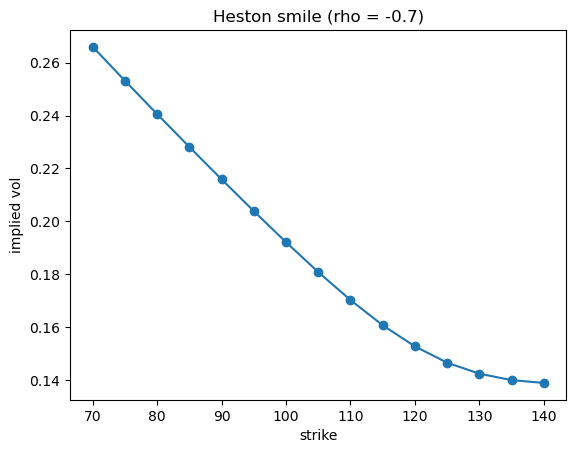

In [4]:
h = Heston(S0=100, v0=0.04, r=0.05, kappa=2.0, theta=0.04, xi=0.5, rho=-0.7)
print("Feller satisfied:", h.feller, "| CF price", round(h.european_price(100, 1.0), 5))
print("MC full truncation", mc.price(h, po.European(100), 1.0, 200_000, n_steps=200))
from derivpricing.analytic import implied_vol
Ks = np.linspace(70, 140, 15)
iv = [implied_vol(h.european_price(K, 1.0), 100, K, 0.05, 1.0) for K in Ks]
plt.plot(Ks, iv, "o-"); plt.xlabel("strike"); plt.ylabel("implied vol"); plt.title("Heston smile (rho = -0.7)"); plt.show()

## 4. Merton jump-diffusion

In [5]:
m = MertonJD(S0=100, r=0.05, sigma=0.2, lam=0.75, mu_j=-0.1, sigma_j=0.2)
for K in (80, 100, 120):
    print(K, "series", round(m.european_price(K, 1.0), 4), "| Fourier", round(m.european_price(K, 1.0, method="cf"), 4),
          "| MC", mc.price(m, po.European(K), 1.0, 200_000))

80 series 26.1258 | Fourier 26.1258 | MC MCResult(price=26.102057, stderr=0.037347, n=100,000, 95% CI=[26.028857, 26.175256])
100 series 12.948 | Fourier 12.948 | MC MCResult(price=12.932413, stderr=0.033759, n=100,000, 95% CI=[12.866247, 12.998579])
120 series 5.296 | Fourier 5.296 | MC MCResult(price=5.278116, stderr=0.026865, n=100,000, 95% CI=[5.225462, 5.330771])


## 5. American put: LSMC vs PDE vs binomial

In [6]:
paths = mc.simulate(GBM(40, 0.06, 0.2), 1.0, 100_000, 50, seed=1, antithetic=True)
print("CRR binomial (2000)", round(binomial_crr(40, 40, 0.06, 0.2, 1.0, 2000), 4))
print("Crank-Nicolson PDE ", round(bs_fd(40, 40, 0.06, 0.2, 1.0, "put", american=True), 4))
for b in ("laguerre", "hermite", "monomial"):
    print(f"LSMC {b:9s}", [round(lsmc_american(paths, 40, 0.06, "put", b, k), 4) for k in (2, 3, 4)])

CRR binomial (2000) 2.3194
Crank-Nicolson PDE  2.3186


LSMC laguerre  [2.291, 2.2976, 2.3052]


LSMC hermite   [2.2701, 2.2989, 2.3051]


LSMC monomial  [2.2701, 2.2989, 2.3051]


## 6. CIR: bond option three ways

Feller: True | P(0,1) closed 0.949646 | PDE 0.949646
ZCB call closed (ncx2) 0.39406
ZCB call implicit PDE  0.39401


ZCB call Monte Carlo   MCResult(price=0.391337, stderr=0.002592, n=200,000, 95% CI=[0.386256, 0.396418])


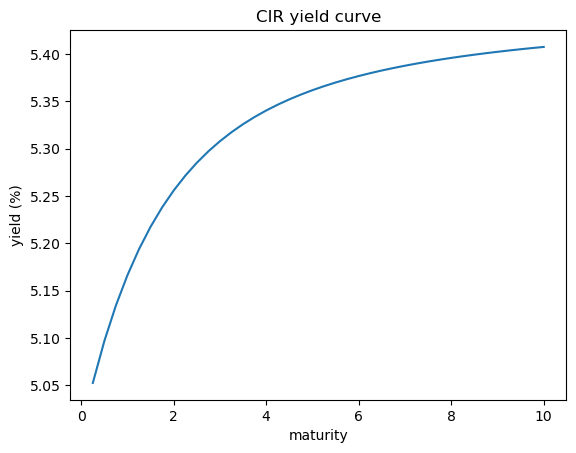

In [7]:
c = CIR(r0=0.05, kappa=0.92, theta=0.055, sigma=0.12)
print("Feller:", c.feller, "| P(0,1) closed", round(c.zcb(1.0), 6), "| PDE", round(zcb_pde(c, 1.0), 6))
print("ZCB call closed (ncx2)", round(c.zcb_option(0.5, 1.0, 980, "call", 1000), 5))
print("ZCB call implicit PDE ", round(zcb_option_pde(c, 0.5, 1.0, 980, "call", 1000), 5))
print("ZCB call Monte Carlo  ", c.mc_zcb_option(0.5, 1.0, 980, "call", 1000, n_paths=200_000))
T = np.linspace(0.25, 10, 40)
plt.plot(T, c.yield_curve(T) * 100); plt.xlabel("maturity"); plt.ylabel("yield (%)"); plt.title("CIR yield curve"); plt.show()

## 7. G2++: closed form vs Monte Carlo across the factor correlation

In [8]:
for rho in (-0.7, 0.0, 0.7):
    g2 = G2pp(0.1, 0.3, 0.05, 0.09, rho, 0.055)
    print(f"rho={rho:+.1f}  closed {g2.zcb_option(0.5, 1, 950, 'put', 1000):.4f}  MC", g2.mc_zcb_option(0.5, 1, 950, "put", 1000, n_paths=200_000, n_steps=100))
g2 = G2pp(0.1, 0.3, 0.05, 0.09, 0.7, 0.055)
print("5y quarterly cap at 5.5%: G2++", round(cap(g2, np.arange(0.25, 5, 0.25), 0.25, 0.055), 5), "| CIR", round(cap(c, np.arange(0.25, 5, 0.25), 0.25, 0.055), 5))

rho=-0.7  closed 0.9789  MC MCResult(price=0.976780, stderr=0.007943, n=100,000, 95% CI=[0.961211, 0.992348])


rho=+0.0  closed 3.7649  MC MCResult(price=3.760008, stderr=0.019274, n=100,000, 95% CI=[3.722231, 3.797785])


rho=+0.7  closed 6.1716  MC MCResult(price=6.184324, stderr=0.027083, n=100,000, 95% CI=[6.131243, 6.237405])
5y quarterly cap at 5.5%: G2++ 0.18315 | CIR 0.02663
